# A shocks with price-aware re-timing

`semi_endo_A_standard.ipynb` shows that a uniform multiplicative `A` shock leaves every
firm's optimal lag unchanged. That result is **partial equilibrium**: it holds the firm's
price and demand environment fixed. It does not survive once firms look at the path of the
price index, because the shock tilts that path and therefore changes *when* it is most
profitable to deliver.

## The firm's problem

With CES demand $y_i = (p_i/P)^{-\sigma} C$ and the markup rule $p_i = \frac{\sigma}{\sigma-1} MC_i$,
realized profit is

$$\pi_i \;\propto\; MC_i^{1-\sigma}\, P^{\sigma}\, C .$$

Marginal cost is inversely proportional to productivity, $MC_i \propto 1/[A\cdot \text{tprod}_i(t)]$
with $\text{tprod}_i(t) = (\beta c)^t (t + N_i)$, and this model closes demand with
$C = P^{\,\text{power}}$. A firm choosing lag $t$ delivers at $t+1$, so

$$V_i(t) \;=\; \big[A\,\text{tprod}_i(t)\big]^{\sigma-1}\; P_{t+1}^{\;\sigma + \text{power}} .$$

`A` still factors out of the argmax — the neutrality result was not wrong. But $P_{t+1}$ does
**not** factor out, and the shock moves the whole $P$ path. That is the channel.

Note the sign: $\sigma + \text{power} > 0$ for any sensible calibration, so a firm wants to
deliver when the price index is **high** — which is when the most competitors are
constrained. Re-timing is a *strategic complement*, and that turns out to drive everything
below.

## Solution

The lag distribution determines the price path and the price path determines the lag
distribution, so this is a fixed point:

1. start from the pre-shock (static) lag distribution;
2. compute the price path it implies;
3. let every firm best-respond to that path;
4. repeat until the distribution stops moving.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
sigma = 5
gamma = 1
eta   = 2
power = (1 + eta) / (-gamma - eta)

beta  = 1 / (1.0 + 0.01)
beta1 = 1 / (1.0 + 0.01 * np.exp(30 / (36.5 * 0.9)))

SHOCK = 0.97          # baseline 3% productivity decline
TMAX  = 20            # longest lag a firm may choose
EXP   = sigma + power # demand-shifter exponent on the price index

print(f'power = {power}, sigma - 1 = {sigma - 1}, sigma + power = {EXP}')

power = -1.0, sigma - 1 = 4, sigma + power = 4.0


## Calibration

Unchanged from `semi_endo_A.ipynb`.

In [3]:
data     = pd.read_csv('APP_data_usa_goods.csv', index_col=0)
data_tau = data['invtCogsRatio'] * 36.5 / (30 * 0.1)

c_grid   = np.linspace(0, 0.99, 1000)
tau_diff = np.zeros(len(c_grid))
for i, c_try in enumerate(c_grid[1:], start=1):
    N_try = -(data_tau) - 1 / np.log(beta * c_try)
    t1 = np.clip(-1 / np.log(beta  * c_try) - N_try, 0, None)
    t2 = np.clip(-1 / np.log(beta1 * c_try) - N_try, 0, None)
    tau_diff[i] = np.mean(np.abs(t1 - t2))
c = np.min(c_grid[np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1))])

N   = np.asarray(-data_tau - 1 / np.log(beta * c))
tau = np.clip(-1 / np.log(beta * c) - N, 0, None)
tau_floor, tau_ceil = np.floor(tau), np.ceil(tau)
tp_c = (beta * c) ** tau_ceil  * (tau_ceil  + N)
tp_f = (beta * c) ** tau_floor * (tau_floor + N)
tau  = np.clip(np.where(tp_c > tp_f, tau_ceil, np.where(tp_c < tp_f, tau_floor, tau)), 0, None).astype(int)

tau_static = tau[::-1].copy()
N_v        = N[::-1].copy()
n_firms    = len(tau_static)
print(f'calibrated c = {c:.6f};  {n_firms} firms, tau in [{tau_static.min()}, {tau_static.max()}]')

calibrated c = 0.901802;  269 firms, tau in [0, 13]


## Payoff grid

`tprod` turns negative for firms with `N < 0` at short lags. Those choices are infeasible
(productivity cannot be negative) and must be excluded explicitly — with `sigma - 1 = 4`,
raising a negative productivity to an even power would otherwise make it look attractive.

In [4]:
T        = np.arange(0, TMAX + 1)
FEASIBLE = (T[None, :] + N_v[:, None]) > 0
TPROD    = np.where(FEASIBLE, (beta * c) ** T[None, :] * (T[None, :] + N_v[:, None]), np.nan)

assert np.array_equal(T[np.nanargmax(TPROD, axis=1)], tau_static), \
    'static grid argmax disagrees with the floor/ceil rounding'
print('static grid argmax reproduces the floor/ceil tau')

static grid argmax reproduces the floor/ceil tau


In [5]:
def shock_mask(t):
    '''Boolean (period x firm) mask of shocked cells; placement as in semi_endo_A.ipynb.'''
    t = np.asarray(t)
    n = len(t) + int(t.min())
    m = int(t.max()) + int(t.min())
    missing_count = len(set(range(int(t.max()) + 1)) - set(t.tolist()))
    M = np.zeros((m + 2, n + missing_count), dtype=bool)
    count = 0
    for i in range(1, m + 2):
        k = int((t == i - 1).sum())
        for j in range(k):
            M[i, n - i - j - count] = True
        if k > 1:
            count += k - 1
    M = np.vstack([M, np.zeros(n + missing_count, dtype=bool)])
    return M[:, 0:n - int(t.min())]


def price_path(tv, shock):
    '''CES price index path implied by a lag distribution.'''
    tp = (beta * c) ** tv * (tv + N_v)
    A  = np.where(shock_mask(tv), shock, 1.0)
    return (np.sum(1 / (A * tp) ** (1 - sigma), axis=1)) ** (1 / (1 - sigma))


def best_response(P):
    '''Each firm's optimal lag given a price path (delivery at t+1).'''
    Pn = P / P[0]
    D = np.ones(max(len(Pn), TMAX + 2))
    D[:len(Pn)] = Pn ** EXP
    D[len(Pn):] = Pn[-1] ** EXP
    V = np.where(FEASIBLE, TPROD ** (sigma - 1) * D[T + 1][None, :], -np.inf)
    return T[V.argmax(axis=1)]


# a flat price path must return the static solution
assert np.array_equal(best_response(np.ones(10)), tau_static), \
    'flat price path should reproduce the static lag distribution'
print('flat price path reproduces the static solution')

flat price path reproduces the static solution


In [6]:
def fixed_point(shock, tv0=None, max_iter=100, verbose=False):
    '''Iterate lag distribution <-> price path to convergence.'''
    tv = (tau_static if tv0 is None else np.asarray(tv0, dtype=int)).copy()
    for it in range(max_iter):
        new = best_response(price_path(tv, shock))
        moved = int((new != tv).sum())
        if verbose:
            print(f'  iter {it:2d}: {moved:3d} firms move, mean tau {new.mean():.3f}')
        if moved == 0:
            return tv, it
        tv = new
    return tv, -1


def irf(tv, shock, L=16):
    '''Consumption and inflation paths for a lag distribution.'''
    P = price_path(tv, shock)
    C = P ** power / P[0] ** power - 1
    pad = np.zeros(len(C) + 1); pad[1:] = C
    pi = -(pad[1:] - pad[:-1])
    a = np.zeros(L); a[:min(L, len(C))]  = C[:L]
    b = np.zeros(L); b[:min(L, len(pi))] = pi[:L]
    return a, b


print('fixed point at the baseline shock:')
tau_fp, iters = fixed_point(SHOCK, verbose=True)
print(f'converged after {iters} iterations; {int((tau_fp != tau_static).sum())} of {n_firms} firms re-time')

fixed point at the baseline shock:
  iter  0:  81 firms move, mean tau 2.751
  iter  1:  49 firms move, mean tau 2.680
  iter  2:  14 firms move, mean tau 2.576
  iter  3:   9 firms move, mean tau 2.565
  iter  4:   2 firms move, mean tau 2.550
  iter  5:   2 firms move, mean tau 2.546
  iter  6:   1 firms move, mean tau 2.550
  iter  7:   0 firms move, mean tau 2.550
converged after 7 iterations; 127 of 269 firms re-time


## Static vs price-aware response

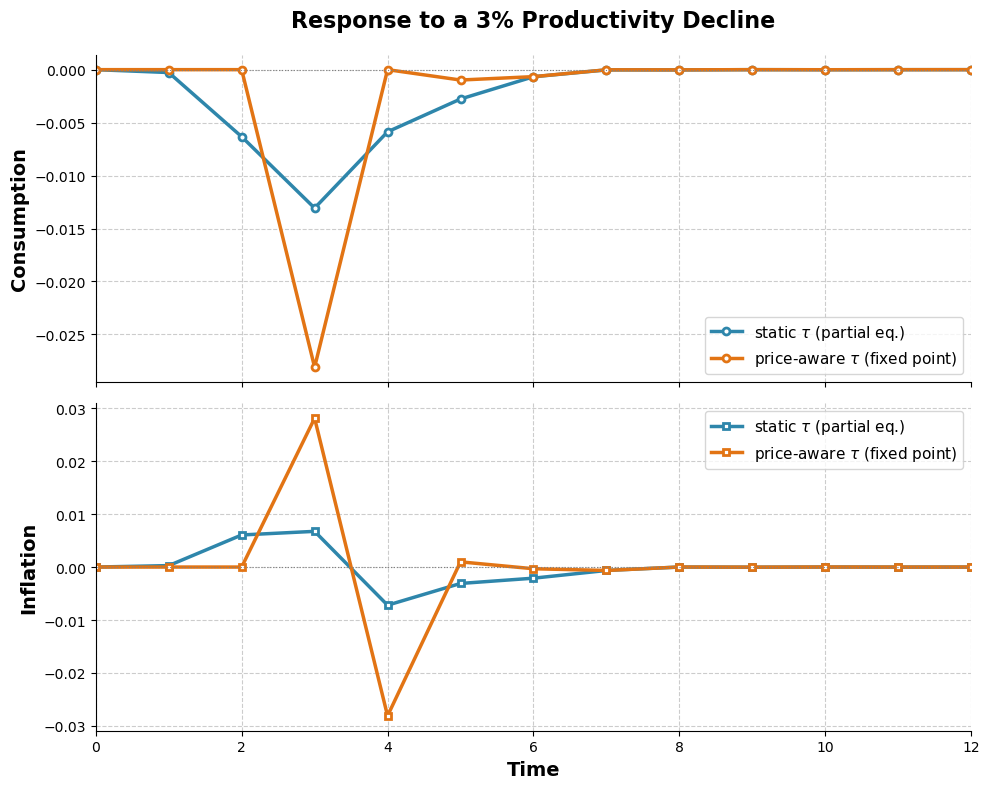

C trough : static -0.01307   price-aware -0.02810   (+115%)
pi peak  : static +0.00674   price-aware +0.02810   (+317%)


In [7]:
C_static, pi_static = irf(tau_static, SHOCK)
C_price,  pi_price  = irf(tau_fp,     SHOCK)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
for ax, ys, lab in ((ax1, (C_static, C_price), 'Consumption'),
                    (ax2, (pi_static, pi_price), 'Inflation')):
    mk = 'o' if lab == 'Consumption' else 's'
    ax.plot(ys[0], lw=2.5, marker=mk, markersize=5, color='#2E86AB',
            markerfacecolor='white', markeredgewidth=2, label='static $\\tau$ (partial eq.)')
    ax.plot(ys[1], lw=2.5, marker=mk, markersize=5, color='#E27414',
            markerfacecolor='white', markeredgewidth=2, label='price-aware $\\tau$ (fixed point)')
    ax.set_ylabel(lab, fontsize=14, weight='bold')
    ax.set_xlim(0, 12)
    ax.grid(True, linestyle='--', alpha=0.4, color='gray')
    ax.axhline(0, color='gray', linestyle=':', linewidth=0.8)
    ax.legend(fontsize=11)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

ax1.set_title(f'Response to a {100*(1-SHOCK):.0f}% Productivity Decline',
              fontsize=16, weight='bold', pad=20)
ax2.set_xlabel('Time', fontsize=14, weight='bold')
plt.tight_layout()
plt.savefig('../semi_endo_A_price_reopt.png', dpi=150)
plt.show()

print(f'C trough : static {C_static.min():+.5f}   price-aware {C_price.min():+.5f}'
      f'   ({100*(C_price.min()/C_static.min()-1):+.0f}%)')
print(f'pi peak  : static {pi_static.max():+.5f}   price-aware {pi_price.max():+.5f}'
      f'   ({100*(pi_price.max()/pi_static.max()-1):+.0f}%)')

## Where the firms go

Because re-timing is a strategic complement, firms move *toward* the crowd rather than away
from it: the lag distribution collapses onto a single date. The staggering that produces the
model's propagation is what unravels.

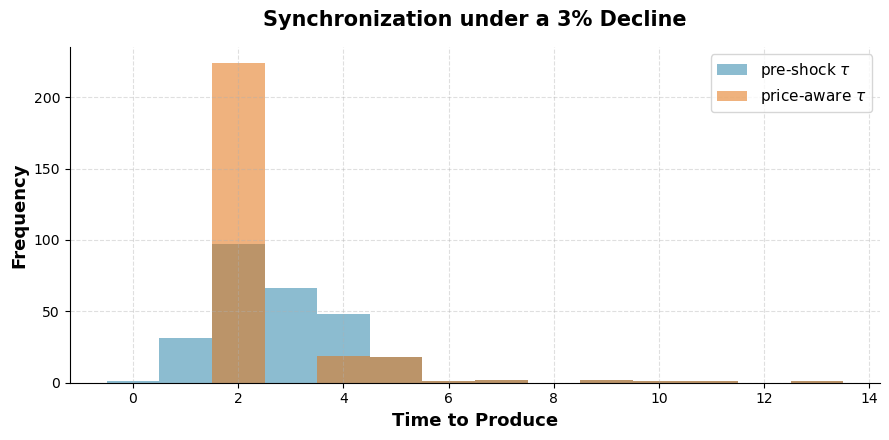

modal lag 2 holds 224 of 269 firms (pre-shock: 97)


In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.arange(-0.5, max(tau_static.max(), tau_fp.max()) + 1.5)
ax.hist(tau_static, bins=bins, alpha=0.55, color='#2E86AB', label='pre-shock $\\tau$')
ax.hist(tau_fp,     bins=bins, alpha=0.55, color='#E27414', label='price-aware $\\tau$')
ax.set_xlabel('Time to Produce', fontsize=13, weight='bold')
ax.set_ylabel('Frequency', fontsize=13, weight='bold')
ax.set_title(f'Synchronization under a {100*(1-SHOCK):.0f}% Decline',
             fontsize=15, weight='bold', pad=15)
ax.legend(fontsize=11)
ax.grid(True, linestyle='--', alpha=0.4)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('../semi_endo_A_price_tau.png', dpi=150)
plt.show()

bc = np.bincount(tau_fp)
print(f'modal lag {bc.argmax()} holds {bc.max()} of {n_firms} firms '
      f'(pre-shock: {np.bincount(tau_static).max()})')

## Is the fixed point unique?

It is not, but the multiplicity is benign: every fixed point found is a synchronized one,
differing only in *which* date firms coordinate on. The aggregate response is nearly
identical across them, so the qualitative conclusion does not depend on the selection.

In [9]:
rng = np.random.default_rng(0)
starts = [tau_static, tau_static + 1, np.maximum(tau_static - 1, 0)]
starts += [np.full(n_firms, k) for k in range(0, 12)]
starts += [rng.integers(0, 10, n_firms) for _ in range(40)]

found = {}
for st in starts:
    f, it = fixed_point(SHOCK, st)
    if it >= 0:
        found[tuple(f.tolist())] = found.get(tuple(f.tolist()), 0) + 1

print(f'{len(found)} distinct fixed points from {len(starts)} starting distributions')
print(f'{"basin":>6} {"mean tau":>9} {"modal lag (share)":>20} {"C trough":>11}')
for k, v in sorted(found.items(), key=lambda kv: -kv[1]):
    a = np.array(k); C_, _ = irf(a, SHOCK); bc = np.bincount(a)
    print(f'{v:>6} {a.mean():>9.3f} {bc.argmax():>10d} ({bc.max():>3d}/{n_firms}) {C_.min():>11.5f}')

4 distinct fixed points from 55 starting distributions
 basin  mean tau    modal lag (share)    C trough
    51     2.550          2 (224/269)    -0.02810
     2     3.178          3 (249/269)    -0.02785
     1     2.535          2 (226/269)    -0.02822
     1     3.190          3 (251/269)    -0.02836


## Large shocks: the response becomes shape-invariant

Firms that have not yet been hit re-time into the shocked window. The bigger the shock, the
more the timing incentive dominates the cost of leaving the productivity optimum, so the
lag distribution converges to full synchronization and stops responding to shock size at
all. Beyond roughly a 10% decline the configuration is essentially fixed, the response
collapses to a single-period spike, and consumption falls **one-for-one** with the shock.

In [10]:
pcts = [0.5, 1, 2, 3, 5, 8, 12, 20, 30, 50, 70, 90]
rows = []
for pct in pcts:
    s = 1 - pct / 100
    f, _ = fixed_point(s)
    C_, pi_ = irf(f, s)
    bc = np.bincount(f)
    rows.append((pct, int((f != tau_static).sum()), f.mean(), bc.max() / n_firms,
                 C_.min(), pi_.max()))

print(f'{"shock":>7} {"movers":>7} {"mean tau":>9} {"modal share":>12} {"C trough":>10} {"C/shock":>9}')
for pct, mv, mt, sh, ct, pk in rows:
    print(f'{pct:>6.1f}% {mv:>7d} {mt:>9.3f} {sh:>11.1%} {ct:>10.5f} {ct/(-pct/100):>9.3f}')

  shock  movers  mean tau  modal share   C trough   C/shock
   0.5%      25     2.885       44.6%   -0.00278     0.555
   1.0%      50     2.836       53.5%   -0.00653     0.653
   2.0%     105     2.736       72.9%   -0.01752     0.876
   3.0%     127     2.550       83.3%   -0.02810     0.937
   5.0%     146     2.409       90.3%   -0.04859     0.972
   8.0%     159     2.264       95.2%   -0.07928     0.991
  12.0%     164     2.208       97.0%   -0.11964     0.997
  20.0%     165     2.193       97.4%   -0.19953     0.998
  30.0%     167     2.156       98.1%   -0.29961     0.999
  50.0%     168     2.130       98.5%   -0.49912     0.998
  70.0%     169     2.104       98.9%   -0.69759     0.997
  90.0%     170     2.074       99.3%   -0.87658     0.974


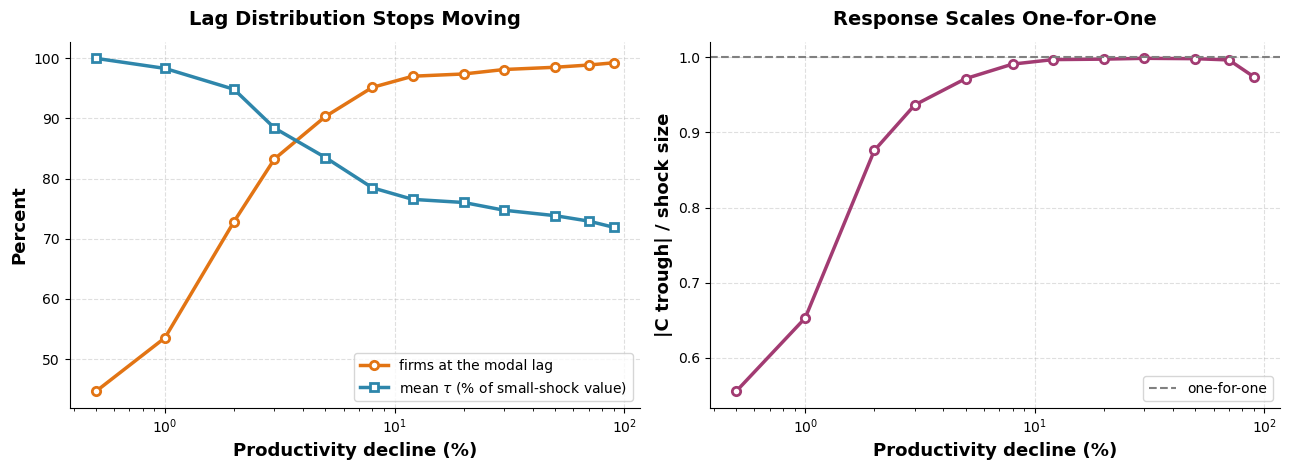

In [11]:
pct_a  = np.array([r[0] for r in rows])
share  = np.array([r[3] for r in rows])
ratio  = np.array([r[4] for r in rows]) / (-pct_a / 100)
meantau = np.array([r[2] for r in rows])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

ax1.plot(pct_a, 100 * share, lw=2.5, marker='o', markersize=6, color='#E27414',
         markerfacecolor='white', markeredgewidth=2, label='firms at the modal lag')
ax1.plot(pct_a, 100 * meantau / meantau[0], lw=2.5, marker='s', markersize=6,
         color='#2E86AB', markerfacecolor='white', markeredgewidth=2,
         label='mean $\\tau$ (% of small-shock value)')
ax1.set_xlabel('Productivity decline (%)', fontsize=13, weight='bold')
ax1.set_ylabel('Percent', fontsize=13, weight='bold')
ax1.set_title('Lag Distribution Stops Moving', fontsize=14, weight='bold', pad=12)
ax1.legend(fontsize=10)

ax2.plot(pct_a, ratio, lw=2.5, marker='o', markersize=6, color='#A23B72',
         markerfacecolor='white', markeredgewidth=2)
ax2.axhline(1.0, color='gray', linestyle='--', lw=1.5, label='one-for-one')
ax2.set_xlabel('Productivity decline (%)', fontsize=13, weight='bold')
ax2.set_ylabel('|C trough| / shock size', fontsize=13, weight='bold')
ax2.set_title('Response Scales One-for-One', fontsize=14, weight='bold', pad=12)
ax2.legend(fontsize=10)

for ax in (ax1, ax2):
    ax.set_xscale('log')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('../semi_endo_A_price_sizes.png', dpi=150)
plt.show()

## Summary

- The neutrality result in `semi_endo_A_standard.ipynb` is a **partial-equilibrium**
  statement. `A` drops out of the firm's argmax, but the shock moves the price path, and
  the price path enters the argmax through $P_{t+1}^{\sigma+\text{power}}$. Once that is
  accounted for, firms do re-time in response to a standard `A` shock.
- The effect is large: at a 3% decline the consumption trough roughly doubles and the
  inflation peak more than quadruples relative to holding lags fixed.
- Because $\sigma + \text{power} > 0$, delivering when the price index is high is
  profitable, so re-timing is a **strategic complement**. Firms move toward the crowd and
  the lag distribution collapses onto one date — the staggering that drives the model's
  propagation unravels into synchronization.
- The fixed point is not unique, but all of them are synchronized and give nearly the same
  aggregate response, so the conclusion is robust to the selection.
- For large shocks the configuration stops changing entirely: past roughly a 10% decline the
  lag distribution is fixed, the response is a single-period spike, and consumption falls
  one-for-one with the shock.

**What this suggests next.** Frictionless re-timing under CES complementarity always
synchronizes, so keeping staggering alive requires something to push against it — a cost of
deviating from the pre-shock lag, idiosyncratic dispersion in the timing benefit, or a limit
on how far a firm may move per period. A `delta`-style split, where only some firms may
re-time, now has real work to do: with the price channel live, being unable to re-time is
genuinely costly.